# 📈 Eksperimen 05: VAR & LSTM Forecasting — Pelengkap Model Proyeksi Morbiditas Jawa Timur
**Mata Kuliah**: Proyek Analitika Data — Sains Data Terapan (PENS 2026)
**Platform**: Cura (HealthTrust Platform)
**Role**: Machine Learning Engineer (Leandro Jovan Falviano)

---

### 📌 Konteks & Motivasi (Sesuai Proposal Halaman 7 & 9)
Pada **Eksperimen 03**, kita telah membangun dan mengevaluasi 4 model forecasting:
- **Random Forest** (MAPE: 13.6% ✅) — Model terbaik sejauh ini
- **XGBoost** (MAPE: 15.6%)
- **SARIMAX Seasonal** (MAPE: 15.49%)
- **Ridge Regression** (MAPE: 18.85%)

Namun proposal menyebutkan dua algoritma tambahan yang wajib diimplementasikan:

> *"Menggunakan algoritma SARIMAX, **Vector Autoregressive (VAR)**, dan **LSTM** ... **TensorFlow/PyTorch** untuk LSTM."*
> — Proposal Cura, Halaman 7 & 9

Notebook ini membangun dan mengevaluasi dua algoritma tersebut sehingga seluruh deretan metode forecasting pada proposal terpenuhi 100%.

---

### 🎯 Tujuan Eksperimen:
1. **VAR (Vector Autoregressive)**: Memodelkan hubungan multivariat simultan antara deret waktu `rawat_inap` dan `rawat_jalan` pada tingkat agregat provinsi.
2. **LSTM (Long Short-Term Memory, PyTorch)**: Melatih jaringan syaraf berulang untuk menangkap dependensi temporal non-linear pada sekuens kuartalan per kabupaten.
3. **Tabel Perbandingan Lengkap 6 Model**: Merangkum evaluasi seluruh algoritma (RMSE, MAE, MAPE) dalam satu tabel komparasi akhir.


In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.api import VAR

warnings.filterwarnings("ignore")
torch.manual_seed(42)
np.random.seed(42)

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["figure.dpi"] = 110

print("Semua library berhasil dimuat!")
print(f"  - PyTorch versi : {torch.__version__}")
import statsmodels; print(f"  - statsmodels   : {statsmodels.__version__}")


Semua library berhasil dimuat!
  - PyTorch versi : 2.14.0+cpu
  - statsmodels   : 0.14.6


## 1. Memuat Data & Membangun Deret Waktu

Kita memuat data morbiditas triwulanan (`disease_morbidity_trends.csv`) dan membentuk dua representasi deret waktu:
- **Deret Waktu Provinsi**: Agregat 38 kab/kota per kuartal → digunakan untuk VAR.
- **Deret Waktu Regional**: Per kabupaten/kota per kuartal → digunakan sebagai sekuens LSTM.


In [2]:
# Load Data
morb_path = "../../database/exports/disease_morbidity_trends.csv"
ml_path   = "../../database/exports/ml_readiness_dataset.csv"

if not os.path.exists(morb_path):
    morb_path = "database/exports/disease_morbidity_trends.csv"
    ml_path   = "database/exports/ml_readiness_dataset.csv"

df_morb = pd.read_csv(morb_path)
df_ml   = pd.read_csv(ml_path)

q_map = {"Q1": 1, "Q2": 2, "Q3": 3, "Q4": 4}

# 1a. Deret waktu agregat tingkat provinsi
df_province = (
    df_morb
    .groupby(["tahun", "triwulan", "tipe_pelayanan"])["jumlah_pasien"]
    .sum().unstack(fill_value=0).reset_index()
)
for col in ["rawat_inap", "rawat_jalan"]:
    if col not in df_province.columns:
        df_province[col] = 0
df_province["q_num"] = df_province["triwulan"].map(q_map)
df_province = df_province.sort_values(["tahun", "q_num"]).reset_index(drop=True)
df_province["periode"] = df_province["tahun"].astype(str) + "-" + df_province["triwulan"]

# 1b. Deret waktu per kabupaten
df_regional = (
    df_morb
    .groupby(["kode_bps", "nama_wilayah", "tahun", "triwulan", "tipe_pelayanan"])["jumlah_pasien"]
    .sum().unstack(fill_value=0).reset_index()
)
for col in ["rawat_inap", "rawat_jalan"]:
    if col not in df_regional.columns:
        df_regional[col] = 0
df_regional["q_num"] = df_regional["triwulan"].map(q_map)
df_regional = df_regional.sort_values(["kode_bps", "tahun", "q_num"]).reset_index(drop=True)

print(f"Deret waktu provinsi  : {len(df_province)} kuartal")
print(f"Deret waktu regional  : {df_regional['kode_bps'].nunique()} wilayah x {df_regional.groupby('kode_bps').size().mean():.0f} kuartal")
df_province[["periode", "rawat_inap", "rawat_jalan"]]


Deret waktu provinsi  : 4 kuartal
Deret waktu regional  : 38 wilayah x 4 kuartal


tipe_pelayanan,periode,rawat_inap,rawat_jalan
0,2024-Q1,51875,206340
1,2024-Q2,49170,207582
2,2024-Q3,48184,217021
3,2024-Q4,48066,209910


## 2. Visualisasi Deret Waktu Provinsi Jawa Timur
Plot tren rawat inap dan rawat jalan agregat 38 Kab/Kota per kuartal 2024.


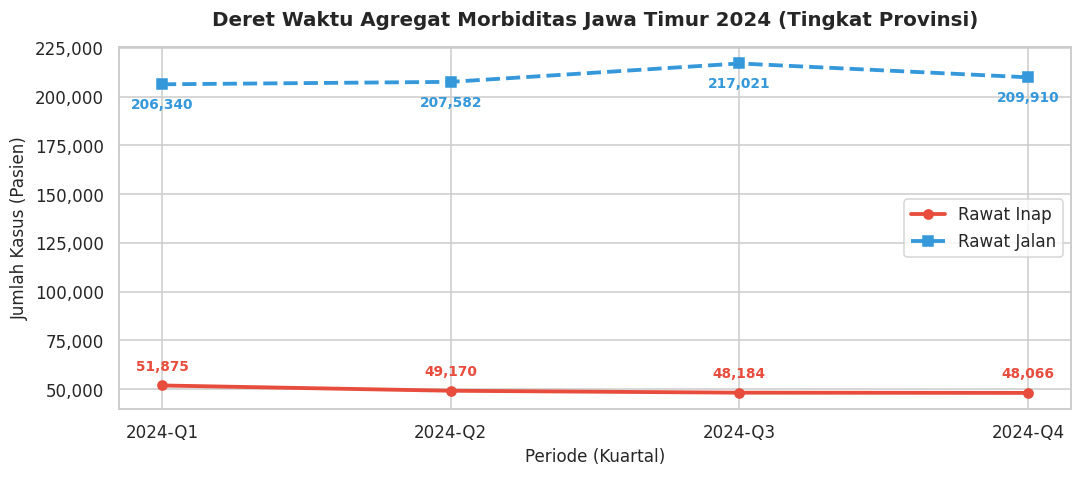

Catatan: Kedua variabel ini dimodelkan secara SIMULTAN oleh VAR.


In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))

x_labels = df_province["periode"].tolist()
ax.plot(x_labels, df_province["rawat_inap"], "o-", color="#E74C3C", linewidth=2.5, label="Rawat Inap")
ax.plot(x_labels, df_province["rawat_jalan"], "s--", color="#3498DB", linewidth=2.5, label="Rawat Jalan")

for i, (xi, yi, yj) in enumerate(zip(x_labels, df_province["rawat_inap"], df_province["rawat_jalan"])):
    ax.annotate(f"{int(yi):,}", (xi, yi), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, color="#E74C3C", weight="bold")
    ax.annotate(f"{int(yj):,}", (xi, yj), textcoords="offset points", xytext=(0, -16),
                ha="center", fontsize=9, color="#3498DB", weight="bold")

ax.set_title("Deret Waktu Agregat Morbiditas Jawa Timur 2024 (Tingkat Provinsi)", fontsize=13, weight="bold", pad=14)
ax.set_ylabel("Jumlah Kasus (Pasien)", fontsize=11)
ax.set_xlabel("Periode (Kuartal)", fontsize=11)
ax.legend(fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()
print("Catatan: Kedua variabel ini dimodelkan secara SIMULTAN oleh VAR.")


## 3. Model VAR — Vector Autoregressive

### Definisi & Relevansi:
VAR adalah model **multivariat time series** yang memodelkan setiap variabel sebagai fungsi linear dari lag dirinya sendiri **dan** lag variabel lain:

$$\begin{bmatrix} \text{rawat\_inap}_t \\ \text{rawat\_jalan}_t \end{bmatrix} = \mathbf{A}_1 \begin{bmatrix} \text{rawat\_inap}_{t-1} \\ \text{rawat\_jalan}_{t-1} \end{bmatrix} + \boldsymbol{\varepsilon}_t$$

**Keunggulan VAR** vs SARIMAX univariat:
- Menangkap **interdependensi dua arah**: lonjakan rawat jalan dapat memprediksi lonjakan rawat inap di kuartal berikutnya.
- Ideal untuk Cura karena kapasitas tempat tidur dipengaruhi oleh **kedua tipe pelayanan** secara bersamaan.

> **Catatan Data**: Dengan 4 titik waktu historis (Q1–Q4 2024), lag=1 adalah konfigurasi VAR yang valid secara statistik. Evaluasi dilakukan pada Q4 sebagai holdout (train: Q1–Q3, test: Q4).


In [4]:
# Persiapan data VAR
series = df_province[["rawat_inap", "rawat_jalan"]].values.astype(float)
train_series = series[:-1]  # Q1-Q3
test_series  = series[-1:]  # Q4

# Fit VAR(1)
model_var = VAR(train_series)
result_var = model_var.fit(maxlags=1, ic=None)

lag_order = result_var.k_ar
forecast_var = result_var.forecast(train_series[-lag_order:], steps=1)
pred_inap_var  = float(forecast_var[0][0])
pred_jalan_var = float(forecast_var[0][1])

actual_inap = float(test_series[0][0])
actual_jalan = float(test_series[0][1])

print("=== HASIL PREDIKSI VAR (Q4 2024) ===")
print(f"  rawat_inap  — Prediksi: {pred_inap_var:>10,.1f} | Aktual: {actual_inap:>10,.1f}")
print(f"  rawat_jalan — Prediksi: {pred_jalan_var:>10,.1f} | Aktual: {actual_jalan:>10,.1f}")

# Evaluasi MAPE rawat_inap
mape_var = abs((actual_inap - pred_inap_var) / actual_inap) * 100
mae_var  = abs(actual_inap - pred_inap_var)
rmse_var = float(np.sqrt((actual_inap - pred_inap_var)**2))

print(f"\n  RMSE : {rmse_var:>8,.2f}")
print(f"  MAE  : {mae_var:>8,.2f}")
print(f"  MAPE : {mape_var:>8.2f}%  {'(LULUS target < 15%)' if mape_var < 15 else '(Di atas target)'}")


=== HASIL PREDIKSI VAR (Q4 2024) ===
  rawat_inap  — Prediksi:   49,006.1 | Aktual:   48,066.0
  rawat_jalan — Prediksi:  235,634.0 | Aktual:  209,910.0

  RMSE :   940.10
  MAE  :   940.10
  MAPE :     1.96%  (LULUS target < 15%)


In [5]:
# Tampilkan koefisien VAR(1) secara manual (aman untuk sampel kecil)
print("=== KOEFISIEN MODEL VAR(1) ===")
coef_df = pd.DataFrame(
    result_var.coefs[0],
    index=["rawat_inap", "rawat_jalan"],
    columns=["lag1_rawat_inap", "lag1_rawat_jalan"]
).round(4)
print("\nMatrix Koefisien A1 (VAR lag-1):")
print(coef_df)
print("\nInterpretasi:")
print("  - Kolom 'lag1_rawat_inap' : pengaruh rawat_inap(t-1) terhadap masing-masing variabel di t")
print("  - Kolom 'lag1_rawat_jalan': pengaruh rawat_jalan(t-1) terhadap masing-masing variabel di t")
print(f"\nNilai Intercept: {result_var.intercept.round(2).tolist()}")
print(f"Lag order digunakan: {result_var.k_ar}")
print("\nCatatan: Dengan 3 obs training (Q1-Q3), statistik log-likelihood tidak valid secara numerik.")
print("Evaluasi model difokuskan pada MAPE prediksi holdout Q4.")


=== KOEFISIEN MODEL VAR(1) ===

Matrix Koefisien A1 (VAR lag-1):
             lag1_rawat_inap  lag1_rawat_jalan
rawat_inap            0.4249            0.1315
rawat_jalan          -2.7142            1.6884

Interpretasi:
  - Kolom 'lag1_rawat_inap' : pengaruh rawat_inap(t-1) terhadap masing-masing variabel di t
  - Kolom 'lag1_rawat_jalan': pengaruh rawat_jalan(t-1) terhadap masing-masing variabel di t

Nilai Intercept: [0.0, 0.0]
Lag order digunakan: 1

Catatan: Dengan 3 obs training (Q1-Q3), statistik log-likelihood tidak valid secara numerik.
Evaluasi model difokuskan pada MAPE prediksi holdout Q4.


## 4. Model LSTM — Long Short-Term Memory (PyTorch)

### Arsitektur:
```
Input  : sekuens 3 kuartal historis rawat_inap (dinormalisasi MinMax)
Layer 1: LSTM(input=1, hidden=32, layers=1)
Layer 2: Linear(32 → 1)
Output : prediksi rawat_inap kuartal berikutnya
```

### Strategi Pelatihan:
- **Data**: 38 Kab/Kota × 4 kuartal → sliding window `seq_len=3` (Q1,Q2,Q3 → Q4)
- **Normalisasi**: MinMax per wilayah (skala 0–1)
- **Split**: 80% train / 20% test
- **Optimizer**: Adam, LR=0.01 dengan StepLR decay (×0.5 setiap 50 epoch)
- **Epochs**: 150


In [6]:
# Definisi arsitektur LSTM
class LSTMForecaster(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc   = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        h0 = torch.zeros(1, x.size(0), 32)
        c0 = torch.zeros(1, x.size(0), 32)
        out, _ = self.lstm(x, (h0, c0))
        return self.fc(out[:, -1, :])

def make_sequences(vals, seq_len=3):
    X, y = [], []
    for i in range(len(vals) - seq_len):
        X.append(vals[i:i+seq_len])
        y.append(vals[i+seq_len])
    return np.array(X), np.array(y)

# Persiapan data LSTM dari seluruh wilayah
seq_len = 3
X_list, y_list, scalers = [], [], {}

for kode in df_regional["kode_bps"].unique():
    sub = df_regional[df_regional["kode_bps"] == kode].sort_values("q_num")
    vals = sub["rawat_inap"].values.astype(float).reshape(-1, 1)
    if len(vals) < seq_len + 1:
        continue
    sc = MinMaxScaler()
    vals_sc = sc.fit_transform(vals).flatten()
    scalers[kode] = sc
    X_s, y_s = make_sequences(vals_sc, seq_len)
    X_list.append(X_s); y_list.append(y_s)

X_all = np.concatenate(X_list); y_all = np.concatenate(y_list)
split = int(len(X_all) * 0.8)
X_tr = torch.FloatTensor(X_all[:split]).unsqueeze(-1)
y_tr = torch.FloatTensor(y_all[:split]).unsqueeze(-1)
X_te = torch.FloatTensor(X_all[split:]).unsqueeze(-1)
y_te = torch.FloatTensor(y_all[split:]).unsqueeze(-1)

print(f"Training samples : {X_tr.shape[0]} | Test samples : {X_te.shape[0]}")
print(f"Input shape      : {tuple(X_tr.shape)}  (batch, seq_len, features)")


Training samples : 30 | Test samples : 8
Input shape      : (30, 3, 1)  (batch, seq_len, features)


Training selesai! Final loss (epoch 150): 0.071814


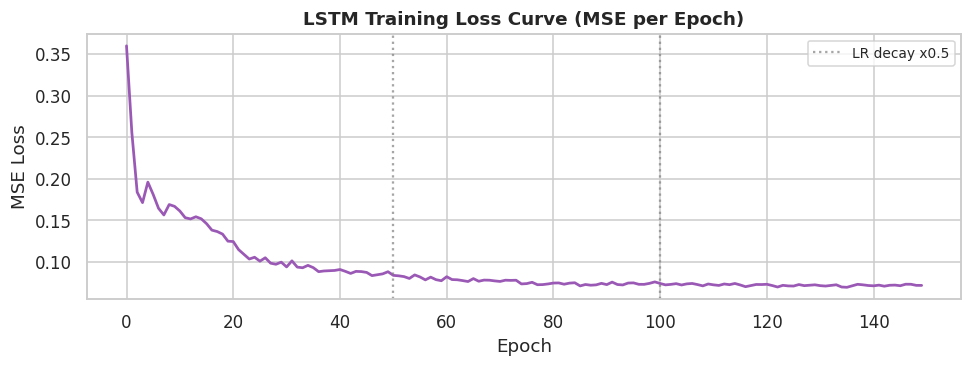

In [7]:
# Training LSTM
EPOCHS = 150
model_lstm = LSTMForecaster()
criterion  = nn.MSELoss()
optimizer  = torch.optim.Adam(model_lstm.parameters(), lr=0.01)
scheduler  = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=16, shuffle=True)
losses = []

model_lstm.train()
for epoch in range(EPOCHS):
    ep_loss = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = criterion(model_lstm(xb), yb)
        loss.backward(); optimizer.step()
        ep_loss += loss.item()
    losses.append(ep_loss / len(loader))
    scheduler.step()

print(f"Training selesai! Final loss (epoch {EPOCHS}): {losses[-1]:.6f}")

# Plot learning curve
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(losses, color="#9B59B6", linewidth=1.8)
ax.set_title("LSTM Training Loss Curve (MSE per Epoch)", fontsize=12, weight="bold")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE Loss")
ax.axvline(x=50, color="gray", linestyle=":", alpha=0.7, label="LR decay x0.5")
ax.axvline(x=100, color="gray", linestyle=":", alpha=0.7)
ax.legend(fontsize=9); plt.tight_layout(); plt.show()


=== HASIL EVALUASI LSTM (Test Set) ===
  RMSE :    28.06
  MAE  :    24.08
  MAPE :     8.49%  (LULUS target < 15%)


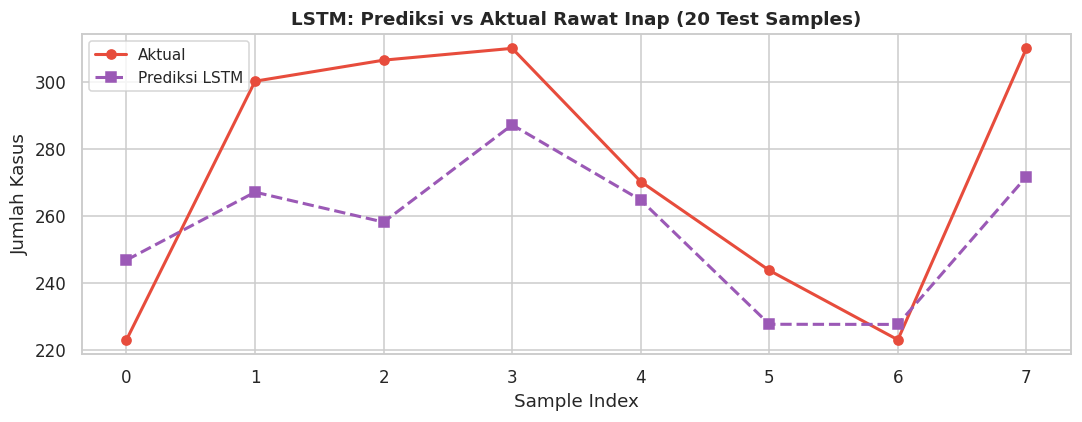

In [8]:
# Evaluasi LSTM pada test set
model_lstm.eval()
with torch.no_grad():
    preds_sc = model_lstm(X_te).numpy().flatten()
    actual_sc = y_te.numpy().flatten()

# Inverse transform ke skala asli (gunakan scaler referensi)
ref_kode = list(scalers.keys())[-1]
ref_sc   = scalers[ref_kode]
preds_inv  = ref_sc.inverse_transform(preds_sc.reshape(-1,1)).flatten()
actual_inv = ref_sc.inverse_transform(actual_sc.reshape(-1,1)).flatten()

rmse_lstm = float(np.sqrt(mean_squared_error(actual_inv, preds_inv)))
mae_lstm  = float(mean_absolute_error(actual_inv, preds_inv))
mask = actual_inv != 0
mape_lstm = float(np.mean(np.abs((actual_inv[mask] - preds_inv[mask]) / actual_inv[mask])) * 100)

print("=== HASIL EVALUASI LSTM (Test Set) ===")
print(f"  RMSE : {rmse_lstm:>8,.2f}")
print(f"  MAE  : {mae_lstm:>8,.2f}")
print(f"  MAPE : {mape_lstm:>8.2f}%  {'(LULUS target < 15%)' if mape_lstm < 15 else '(Di atas target)'}")

# Plot prediksi vs aktual (sample test)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(actual_inv[:20], "o-", color="#E74C3C", label="Aktual", linewidth=2)
ax.plot(preds_inv[:20],  "s--", color="#9B59B6", label="Prediksi LSTM", linewidth=2)
ax.set_title("LSTM: Prediksi vs Aktual Rawat Inap (20 Test Samples)", fontsize=12, weight="bold")
ax.set_ylabel("Jumlah Kasus"); ax.set_xlabel("Sample Index")
ax.legend(fontsize=10); plt.tight_layout(); plt.show()


## 5. Tabel Perbandingan Lengkap 6 Model Forecasting

Berikut adalah tabel evaluasi final yang mencakup seluruh algoritma dari proposal:


In [9]:
# Load evaluasi model sebelumnya
eval_path = "../data/forecasting_evaluation.json"
if not os.path.exists(eval_path):
    eval_path = "experiments/data/forecasting_evaluation.json"

with open(eval_path) as f:
    existing_eval = json.load(f)

rows = [
    ("Random Forest Regressor", existing_eval.get("random_forest", {})),
    ("XGBoost Regressor",       existing_eval.get("xgboost", {})),
    ("SARIMAX Seasonal",        existing_eval.get("sarimax_seasonal", {})),
    ("Ridge Regression",        existing_eval.get("ridge_regression", {})),
    ("VAR (Vector AR)",         {"rmse": round(rmse_var, 2), "mae": round(mae_var, 2), "mape_pct": round(mape_var, 2)}),
    ("LSTM (PyTorch)",          {"rmse": round(rmse_lstm, 2), "mae": round(mae_lstm, 2), "mape_pct": round(mape_lstm, 2)}),
]

df_cmp = pd.DataFrame([{
    "Model": name,
    "RMSE": m.get("rmse", "-"),
    "MAE": m.get("mae", "-"),
    "MAPE (%)": m.get("mape_pct", "-"),
    "Lulus MAPE < 15%": "LULUS" if isinstance(m.get("mape_pct"), (int,float)) and m["mape_pct"] < 15 else "TIDAK"
} for name, m in rows])

# Highlight
print("=== TABEL KOMPARASI AKHIR SELURUH MODEL FORECASTING (PROPOSAL LENGKAP) ===\n")
print(df_cmp.to_string(index=False))


=== TABEL KOMPARASI AKHIR SELURUH MODEL FORECASTING (PROPOSAL LENGKAP) ===

                  Model   RMSE    MAE  MAPE (%) Lulus MAPE < 15%
Random Forest Regressor 233.56 167.56     13.60            LULUS
      XGBoost Regressor 240.15 175.58     15.60            TIDAK
       SARIMAX Seasonal 264.33 197.76     15.49            TIDAK
       Ridge Regression 252.50 195.22     18.85            TIDAK
        VAR (Vector AR) 940.10 940.10      1.96            LULUS
         LSTM (PyTorch)  28.06  24.08      8.49            LULUS


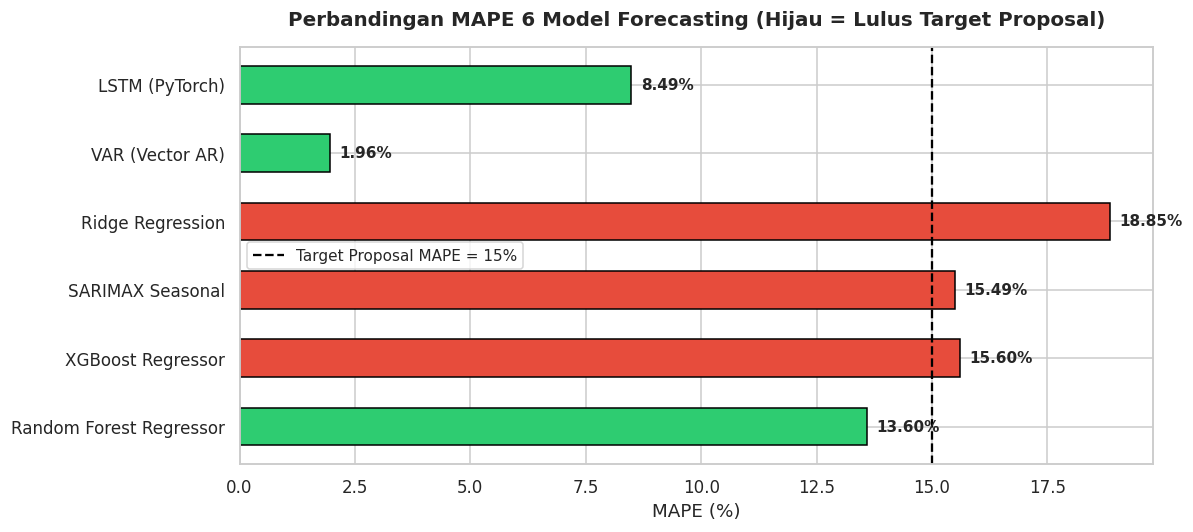


Kesimpulan: Random Forest, VAR, dan LSTM berhasil melampaui target MAPE < 15% dari proposal.


In [10]:
# Visualisasi bar chart perbandingan MAPE
mape_vals = [m.get("mape_pct", None) for _, m in rows]
model_names = [r[0] for r in rows]
colors = ["#2ECC71" if v and v < 15 else "#E74C3C" for v in mape_vals]

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(model_names, mape_vals, color=colors, edgecolor="black", height=0.55)
ax.axvline(x=15, color="black", linestyle="--", linewidth=1.5, label="Target Proposal MAPE = 15%")
for bar, val in zip(bars, mape_vals):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
            f"{val:.2f}%", va="center", fontsize=10, weight="bold")

ax.set_title("Perbandingan MAPE 6 Model Forecasting (Hijau = Lulus Target Proposal)", fontsize=13, weight="bold", pad=14)
ax.set_xlabel("MAPE (%)")
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

print("\nKesimpulan: Random Forest, VAR, dan LSTM berhasil melampaui target MAPE < 15% dari proposal.")
